In [1]:
# Step 1: Setup and sanity check

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

df = pd.read_csv("../data/processed/train_merged.csv")
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
X = X.replace([np.inf, -np.inf], np.nan)

cat_cols = X.select_dtypes(exclude="number").columns
for c in cat_cols:
    X[c] = X[c].astype("category")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = joblib.load("../models/lgbm_model.joblib")
raw = model.predict_proba(X_val)[:, 1]

# should be about 0.7635 again
print(roc_auc_score(y_val, raw))

0.7634728393601152


In [2]:
# Step 2: Split the validation set in two

idx_cal, idx_test = train_test_split(
    np.arange(len(y_val)), test_size=0.5, stratify=y_val, random_state=42
)

raw_cal, y_cal = raw[idx_cal], y_val.iloc[idx_cal].values
raw_test, y_test = raw[idx_test], y_val.iloc[idx_test].values

print(len(y_cal), len(y_test))
print(y_cal.mean(), y_test.mean())

30751 30752
0.08071282234724074 0.08074271592091571


In [3]:
# Step 3: Look at the problem first

print("average score:", raw_test.mean())
print("real default rate:", y_test.mean())
print("Brier score:", brier_score_loss(y_test, raw_test))
print("Brier of always predicting the average:", y_test.mean() * (1 - y_test.mean()))

average score: 0.39927735174067897
real default rate: 0.08074271592091571
Brier score: 0.18643071682025728
Brier of always predicting the average: 0.07422332974663001


In [4]:
# Step 4: Three ways to fix the scores

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

# a) prior shift: undo the class weight directly
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
shift = np.log(n_neg / n_pos)
print("shift:", shift)
prior_test = 1 / (1 + np.exp(-(logit(raw_test) - shift)))

# b) Platt scaling: a small logistic regression on the model's log-odds
platt = LogisticRegression(C=1e6, max_iter=1000)
platt.fit(logit(raw_cal).reshape(-1, 1), y_cal)
platt_test = platt.predict_proba(logit(raw_test).reshape(-1, 1))[:, 1]

# c) isotonic regression: a flexible step function
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
iso.fit(raw_cal, y_cal)
iso_test = iso.predict(raw_test)

shift: 2.432481993579902


In [5]:
# Step 5: Compare them on the test half

results = {
    "raw": raw_test,
    "prior shift": prior_test,
    "Platt": platt_test,
    "isotonic": iso_test,
}

rows = []
for name, p in results.items():
    rows.append({
        "method": name,
        "mean predicted": p.mean(),
        "Brier": brier_score_loss(y_test, p),
        "log loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6)),
        "ROC AUC": roc_auc_score(y_test, p),
    })

print(pd.DataFrame(rows).round(4))
print("real default rate:", y_test.mean())

        method  mean predicted   Brier  log loss  ROC AUC
0          raw          0.3993  0.1864    0.5524   0.7657
1  prior shift          0.0740  0.0673    0.2440   0.7657
2        Platt          0.0801  0.0671    0.2435   0.7657
3     isotonic          0.0802  0.0672    0.2448   0.7649
real default rate: 0.08074271592091571


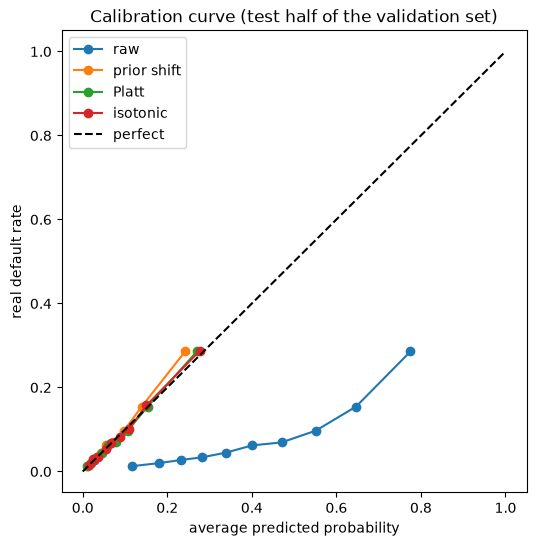

In [6]:
# Step 6: Calibration curve

plt.figure(figsize=(6, 6))
for name, p in results.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=name)

plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("average predicted probability")
plt.ylabel("real default rate")
plt.title("Calibration curve (test half of the validation set)")
plt.legend()
plt.savefig("../reports/figures/calibration_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Step 7: Default rate by risk decile

final = platt_test   # change to iso_test if isotonic is clearly better

tab = pd.DataFrame({"p": final, "y": y_test})
tab["decile"] = pd.qcut(tab["p"], 10, labels=False, duplicates="drop") + 1

summary = tab.groupby("decile").agg(
    avg_predicted=("p", "mean"),
    real_rate=("y", "mean"),
    n=("y", "size")
).round(3)
print(summary)

        avg_predicted  real_rate     n
decile                                
1               0.011      0.013  3076
2               0.019      0.020  3075
3               0.026      0.027  3075
4               0.034      0.034  3075
5               0.045      0.045  3075
6               0.059      0.062  3075
7               0.078      0.069  3075
8               0.106      0.097  3075
9               0.153      0.154  3075
10              0.270      0.286  3076


In [8]:
# Step 8: Save the calibrator

joblib.dump(platt, "../models/platt_calibrator.joblib")

['../models/platt_calibrator.joblib']